In [1]:
!pip install polars scikit-learn mlflow numpy matplotlib seaborn sentence-transformers

In [2]:
import polars as pl
from sklearn.model_selection import cross_validate, train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score, accuracy_score, make_scorer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
import mlflow
import mlflow.sklearn
import numpy as np
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sentence_transformers import SentenceTransformer

/home/julio/Documentos/tcc-ecommerce-nlp-ptbr/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df_reviews_olist = pl.read_csv(
    '../data/olist_order_reviews_dataset.csv'
)
df_reviews_olist

review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
str,str,i64,str,str,str,str
"""7bc2406110b926393aa56f80a40eba…","""73fc7af87114b39712e6da79b0a377…",4,null,null,"""2018-01-18 00:00:00""","""2018-01-18 21:46:59"""
"""80e641a11e56f04c1ad469d5645fdf…","""a548910a1c6147796b98fdf73dbeba…",5,null,null,"""2018-03-10 00:00:00""","""2018-03-11 03:05:13"""
"""228ce5500dc1d8e020d8d1322874b6…","""f9e4b658b201a9f2ecdecbb34bed03…",5,null,null,"""2018-02-17 00:00:00""","""2018-02-18 14:36:24"""
"""e64fb393e7b32834bb789ff8bb3075…","""658677c97b385a9be170737859d351…",5,null,"""Recebi bem antes do prazo esti…","""2017-04-21 00:00:00""","""2017-04-21 22:02:06"""
"""f7c4243c7fe1938f181bec41a392bd…","""8e6bfb81e283fa7e4f11123a3fb894…",5,null,"""Parabéns lojas lannister adore…","""2018-03-01 00:00:00""","""2018-03-02 10:26:53"""
…,…,…,…,…,…,…
"""574ed12dd733e5fa530cfd4bbf39d7…","""2a8c23fee101d4d5662fa670396eb8…",5,null,null,"""2018-07-07 00:00:00""","""2018-07-14 17:18:30"""
"""f3897127253a9592a73be9bdfdf4ed…","""22ec9f0669f784db00fa86d035cf86…",5,null,null,"""2017-12-09 00:00:00""","""2017-12-11 20:06:42"""
"""b3de70c89b1510c4cd3d0649fd3024…","""55d4004744368f5571d1f590031933…",5,null,"""Excelente mochila, entrega sup…","""2018-03-22 00:00:00""","""2018-03-23 09:10:43"""


In [4]:
df_reviews_olist.describe()

statistic,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
str,str,str,f64,str,str,str,str
"""count""","""99224""","""99224""",99224.0,"""11568""","""40977""","""99224""","""99224"""
"""null_count""","""0""","""0""",0.0,"""87656""","""58247""","""0""","""0"""
"""mean""",null,null,4.086421,null,null,null,null
"""std""",null,null,1.347579,null,null,null,null
"""min""","""0001239bc1de2e33cb583967c2ca4c…","""00010242fe8c5a6d1ba2dd792cb162…",1.0,""" """,""" ""","""2016-10-02 00:00:00""","""2016-10-07 18:32:28"""
"""25%""",null,null,4.0,null,null,null,null
"""50%""",null,null,5.0,null,null,null,null
"""75%""",null,null,5.0,null,null,null,null
"""max""","""fffefe7a48d22f7b32046421062219…","""fffe41c64501cc87c801fd61db3f62…",5.0,"""🔟 ""","""😡😡😡😡😡👎👎👎👎👎 Empresa sem compro…","""2018-08-31 00:00:00""","""2018-10-29 12:27:35"""


In [5]:
df_reviews_olist = (
    df_reviews_olist
    .select(['review_comment_message', 'review_score']) 
    .drop_nulls(subset=['review_comment_message', 'review_score'])                                         
    .with_columns(                                                                                
        pl.when(pl.col('review_score') <= 2).then(0)
        .when(pl.col('review_score') == 3).then(1)
        .otherwise(2)
        .alias('label')
    )
)

In [6]:
print(f'Total de instâncias:{df_reviews_olist.shape[0]}')

print(f'\nDistribuição de classes:\n{df_reviews_olist['label'].value_counts(normalize=True) * 100}')

Total de instâncias:40977

Distribuição de classes:
shape: (3, 2)
┌───────┬────────────┐
│ label ┆ proportion │
│ ---   ┆ ---        │
│ f64   ┆ f64        │
╞═══════╪════════════╡
│ 0.0   ┆ 26.575884  │
│ 100.0 ┆ 8.680479   │
│ 200.0 ┆ 64.743637  │
└───────┴────────────┘


In [7]:
X = df_reviews_olist['review_comment_message']
y = df_reviews_olist['label']

In [8]:
vec = TfidfVectorizer()
vec.fit(X)
vocab_size = len(vec.vocabulary_)
print(f"Total de palavras distintas no corpus: {vocab_size}")

Total de palavras distintas no corpus: 15688


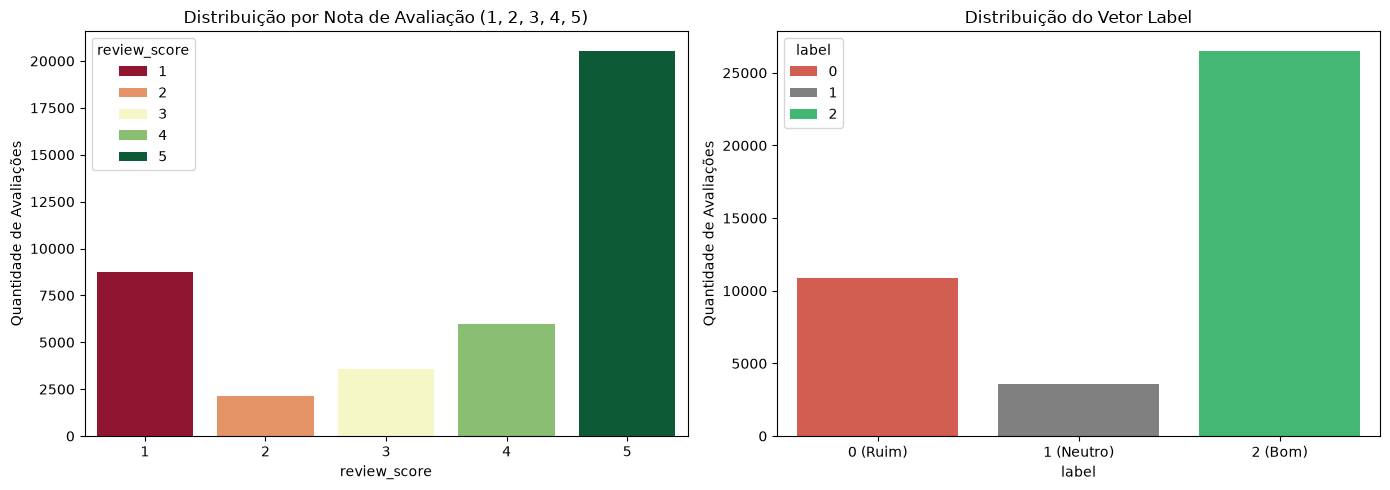

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=df_reviews_olist,
    x='review_score',
    hue='review_score',
    palette='RdYlGn',
    ax=axes[0],
)
axes[0].set_title("Distribuição por Nota de Avaliação (1, 2, 3, 4, 5)")
axes[0].set_ylabel("Quantidade de Avaliações")

sns.countplot(
    data=df_reviews_olist,
    x='label',
    hue='label',
    palette=["#e74c3c", "#808080", "#2ecc71"],
    ax=axes[1],
)
axes[1].set_title("Distribuição do Vetor Label")
axes[1].set_xticks([0, 1, 2])
axes[1].set_xticklabels(['0 (Ruim)', '1 (Neutro)', '2 (Bom)'])
axes[1].set_ylabel("Quantidade de Avaliações")

plt.tight_layout()
plt.show()


In [10]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive_Bayes": MultinomialNB(),
    "SVM_OvO": SVC(kernel='linear', decision_function_shape='ovo', class_weight='balanced', random_state=42),
    "Decision_Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42)
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("Baseline_Olist_TFIDF")

for model_name, classifier in models.items():

    with mlflow.start_run(run_name=f"{model_name}_Olist"):
        
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

        mlflow.log_param("dataset", "Olist")
        mlflow.log_param("representation", "TF-IDF")
        mlflow.log_param("classifier", model_name)
        mlflow.log_param("max_features", "None")

        pipeline = Pipeline([
            ('tfidf', TfidfVectorizer()),
            ('clf', classifier)
        ])

        scoring_metrics = {
            'accuracy': 'accuracy',
            'precision_macro': make_scorer(precision_score, average='macro', zero_division=0),
            'recall_macro': make_scorer(recall_score, average='macro', zero_division=0),
            'f1_macro': make_scorer(f1_score, average='macro', zero_division=0)
        }

        cv_results = cross_validate(
            pipeline, X_train, y_train, 
            cv=skf, 
            scoring=scoring_metrics, 
            n_jobs=-1,
            return_estimator=True
        )
        
        mlflow.log_metric("cv_accuracy_mean", np.mean(cv_results['test_accuracy']))
        mlflow.log_metric("cv_precision_mean", np.mean(cv_results['test_precision_macro']))
        mlflow.log_metric("cv_recall_mean", np.mean(cv_results['test_recall_macro']))
        mlflow.log_metric("cv_f1_macro_mean", np.mean(cv_results['test_f1_macro']))
        
        mlflow.log_metric("cv_f1_macro_std", np.std(cv_results['test_f1_macro']))
        mlflow.log_metric("cv_fit_time_mean", np.mean(cv_results['fit_time']))

        best_fold_index = np.argmax(cv_results['test_f1_macro'])
        best_model = cv_results['estimator'][best_fold_index]
        
        mlflow.log_metric("best_fold_index", best_fold_index)
        
        vocab_size_pipeline = len(best_model.named_steps['tfidf'].vocabulary_)
        mlflow.log_metric("actual_num_features", vocab_size_pipeline)

        y_pred = best_model.predict(X_test)

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
        rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
        f1 = f1_score(y_test, y_pred, average='macro')

        mlflow.log_metric("test_accuracy", acc)
        mlflow.log_metric("test_precision", prec)
        mlflow.log_metric("test_recall", rec)
        mlflow.log_metric("test_f1_score", f1)

        mlflow.sklearn.log_model(
            sk_model=best_model,
            name="model",
            serialization_format="skops",
            skops_trusted_types=["scipy.sparse._csr.csr_matrix"]
        )


In [13]:
X = df_reviews_olist['review_comment_message'].to_list()
y = df_reviews_olist['label'].to_numpy()

In [ ]:
embedding_models = {
    "MiniLM-L6": "sentence-transformers/multi-qa-MiniLM-L6-cos-v1",
    "DistilBERT-Multi": "sentence-transformers/multi-qa-distilbert-cos-v1",
    "BERTimbau": "neuralmind/bert-base-portuguese-cased",
    "RexBERT-Ecom": "thebajajra/RexBERT-large",
    # "BGE-M3": "BAAI/bge-m3",
    # "Qwen-GTE": "Alibaba-NLP/gte-Qwen2-1.5B-instruct"
}

models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    "SVM_OvO": SVC(kernel='linear', decision_function_shape='ovo', class_weight='balanced', random_state=42),
    "Decision_Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42)
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("Embeddings_B2W")

for emb_name, emb_path in embedding_models.items():
    print(f"\n--- Extraindo embeddings usando: {emb_name} ---")
    
    encoder = SentenceTransformer(emb_path, device='cuda')
    
    X_embeddings = encoder.encode(X, show_progress_bar=True)
    
    for clf_name, classifier in models.items():
        print(f"Treinando classificador: {clf_name}...")

        run_name = f"{emb_name}_{clf_name}" 
        
        with mlflow.start_run(run_name=run_name):
            
            X_train, X_test, y_train, y_test = train_test_split(X_embeddings, y, test_size=0.2, random_state=42, stratify=y)
            
            mlflow.log_param("dataset", "B2W")
            mlflow.log_param("representation", emb_name)
            mlflow.log_param("classifier", clf_name)
            
            scoring_metrics = {
                'accuracy': 'accuracy',
                'precision_macro': make_scorer(precision_score, average='macro', zero_division=0),
                'recall_macro': make_scorer(recall_score, average='macro', zero_division=0),
                'f1_macro': make_scorer(f1_score, average='macro', zero_division=0)
            }

            cv_results = cross_validate(
                classifier, X_train, y_train, 
                cv=skf, scoring=scoring_metrics, n_jobs=-1, return_estimator=True
            )
            
            mlflow.log_metric("cv_accuracy_mean", np.mean(cv_results['test_accuracy']))
            mlflow.log_metric("cv_precision_mean", np.mean(cv_results['test_precision_macro']))
            mlflow.log_metric("cv_recall_mean", np.mean(cv_results['test_recall_macro']))
            mlflow.log_metric("cv_f1_macro_mean", np.mean(cv_results['test_f1_macro']))
            mlflow.log_metric("cv_f1_macro_std", np.std(cv_results['test_f1_macro']))
            mlflow.log_metric("cv_fit_time_mean", np.mean(cv_results['fit_time']))

            best_fold_index = np.argmax(cv_results['test_f1_macro'])
            best_model = cv_results['estimator'][best_fold_index]
            mlflow.log_metric("best_fold_index", best_fold_index)
            
            embedding_dim = X_embeddings.shape[1]
            mlflow.log_metric("actual_num_features", embedding_dim)

            y_pred = best_model.predict(X_test)

            acc = accuracy_score(y_test, y_pred)
            prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
            rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
            f1 = f1_score(y_test, y_pred, average='macro')

            mlflow.log_metric("test_accuracy", acc)
            mlflow.log_metric("test_precision", prec)
            mlflow.log_metric("test_recall", rec)
            mlflow.log_metric("test_f1_score", f1)

            mlflow.sklearn.log_model(
                sk_model=best_model,
                name="model"
            )



--- Extraindo embeddings usando: MiniLM-L6 ---


Batches: 100%|██████████| 1281/1281 [00:05<00:00, 237.96it/s]

Treinando classificador: KNN...


Treinando classificador: LogisticRegression...
Treinando classificador: SVM_OvO...
Treinando classificador: Decision_Tree...

--- Extraindo embeddings usando: DistilBERT-Multi ---


Batches: 100%|██████████| 1281/1281 [00:10<00:00, 117.06it/s]


Treinando classificador: KNN...
Treinando classificador: LogisticRegression...
Treinando classificador: SVM_OvO...
Treinando classificador: Decision_Tree...

--- Extraindo embeddings usando: BERTimbau ---


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 69123.52it/s]
[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Batches: 100%|██████████| 1281/1281 [00:22<00:00, 56.27it/s] 


Treinando classificador: KNN...
Treinando classificador: LogisticRegression...
Treinando classificador: SVM_OvO...
